# Climate Comfort Index (CCI) — 02 Exploratory Data Analysis

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. Daily Aggregations & Target Derivation
According to the AT2 specification:
- `temperature_2m`, `relative_humidity_2m`, `wind_speed_10m`, `cloud_cover` -> **Daily Mean**
- `precipitation` -> **Daily Total (Sum)**
- `wind_gusts_10m` -> **Daily Maximum**

Component Scores:
- $\text{TempScore} = \max(0, 1 - |\text{temp} - 22| / 20)$
- $\text{HumidityScore} = \max(0, 1 - |\text{humidity} - 50| / 50)$
- $\text{WindScore} = \max(0, 1 - |\text{wind} - 10| / 40)$
- $\text{CloudScore} = \max(0, 1 - \text{cloud} / 100)$
- $\text{RainScore} = \max(0, 1 - \text{rain} / 20)$
- $\text{CCI} = 100 \times (0.35\text{Temp} + 0.20\text{Hum} + 0.15\text{Wind} + 0.15\text{Cloud} + 0.15\text{Rain})$


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import load_interim_data
from src.targets import calculate_climate_comfort_index, interpret_cci

daily_df = load_interim_data()
print(f"Loaded daily aggregated dataset: {len(daily_df):,} days")
daily_df.head()


Loaded daily aggregated dataset: 2,922 days


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2018-01-01,22.870833,79.833333,10.962500,36.166667,0.0,54.4,0.0
1,2018-01-02,22.137500,83.083333,11.362500,31.833333,0.8,47.2,0.0
2,2018-01-03,20.758333,75.791667,22.075000,75.125000,1.6,64.1,0.0
3,2018-01-04,20.375000,72.333333,11.208333,63.416667,1.2,40.7,0.0
4,2018-01-05,21.308333,76.750000,11.729167,35.291667,0.0,47.2,0.0


## 2. Deriving Component Scores & Climate Comfort Index

In [2]:
cci, comp_dict = calculate_climate_comfort_index(
    temperature_2m=daily_df["temperature_2m"],
    relative_humidity_2m=daily_df["relative_humidity_2m"],
    wind_speed_10m=daily_df["wind_speed_10m"],
    cloud_cover=daily_df["cloud_cover"],
    precipitation=daily_df["precipitation"],
)
daily_df["cci"] = cci
daily_df["cci_category"] = daily_df["cci"].apply(interpret_cci)

print("CCI Summary Statistics:")
print(daily_df["cci"].describe())


CCI Summary Statistics:
count    2922.000000
mean       70.680766
std        10.662368
min        28.634375
25%        64.846875
50%        71.809375
75%        77.880729
max        98.889583
Name: cci, dtype: float64


## 3. Distribution of CCI & Component Scores

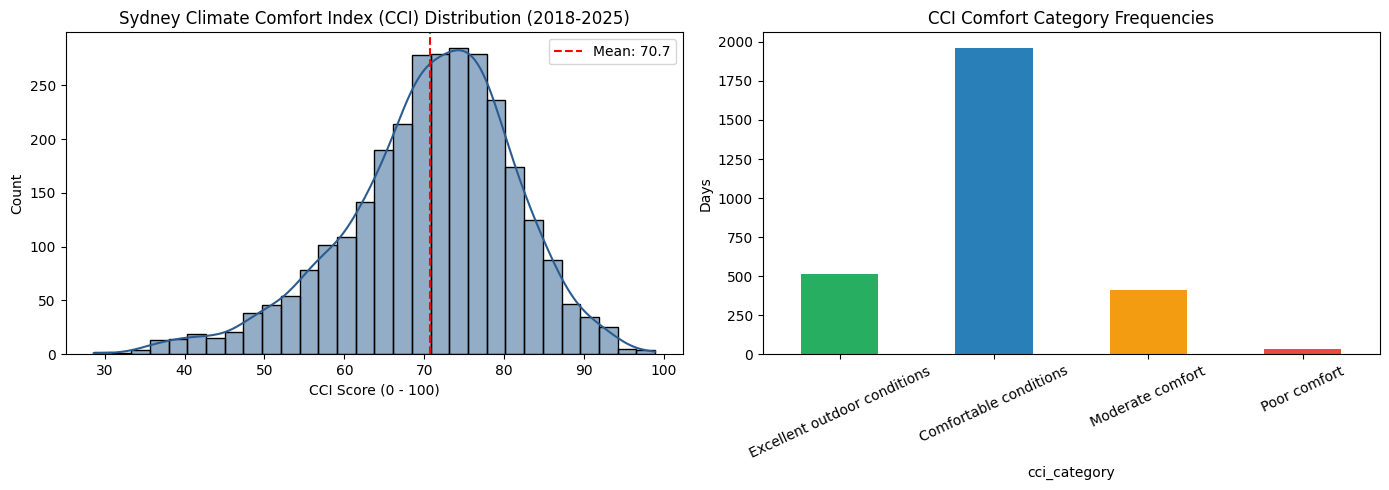

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(daily_df["cci"], kde=True, ax=axes[0], color="#2b5c8f", bins=30)
axes[0].set_title("Sydney Climate Comfort Index (CCI) Distribution (2018-2025)")
axes[0].set_xlabel("CCI Score (0 - 100)")
axes[0].axvline(daily_df["cci"].mean(), color="red", linestyle="--", label=f"Mean: {daily_df['cci'].mean():.1f}")
axes[0].legend()

cat_counts = daily_df["cci_category"].value_counts()[["Excellent outdoor conditions", "Comfortable conditions", "Moderate comfort", "Poor comfort"]]
cat_counts.plot(kind="bar", ax=axes[1], color=["#27ae60", "#2980b9", "#f39c12", "#e74c3c"])
axes[1].set_title("CCI Comfort Category Frequencies")
axes[1].set_ylabel("Days")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("reports/figures/cci_distribution.png", dpi=150)
plt.show()


## 4. Seasonal Dynamics of Outdoor Comfort in Sydney

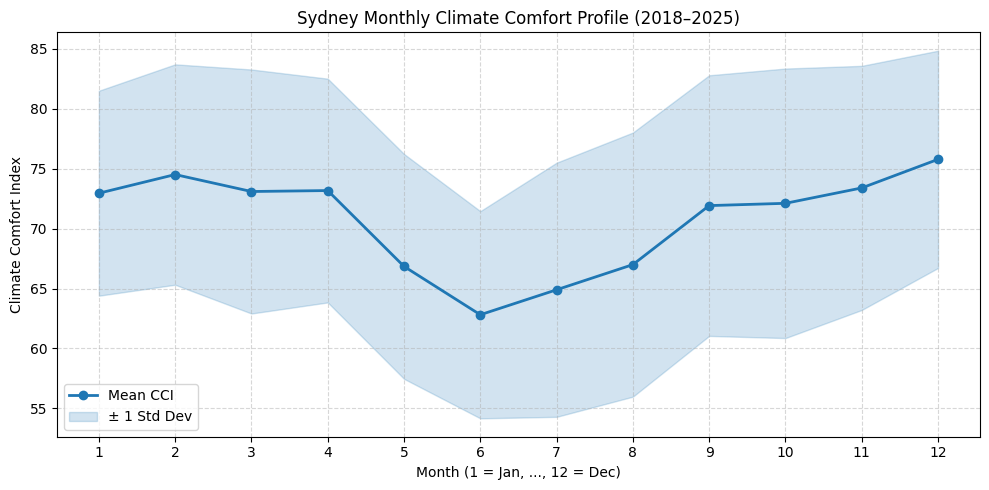

In [4]:
daily_df["month"] = daily_df["date"].dt.month
monthly_cci = daily_df.groupby("month")["cci"].agg(["mean", "std", "min", "max"])

plt.figure(figsize=(10, 5))
plt.plot(monthly_cci.index, monthly_cci["mean"], marker="o", color="#1f77b4", linewidth=2, label="Mean CCI")
plt.fill_between(monthly_cci.index, monthly_cci["mean"] - monthly_cci["std"], monthly_cci["mean"] + monthly_cci["std"], alpha=0.2, color="#1f77b4", label="± 1 Std Dev")
plt.title("Sydney Monthly Climate Comfort Profile (2018–2025)")
plt.xlabel("Month (1 = Jan, ..., 12 = Dec)")
plt.ylabel("Climate Comfort Index")
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("reports/figures/cci_seasonal_profile.png", dpi=150)
plt.show()


## 5. Key EDA Findings
1. **Comfort Distribution**: The overall mean CCI for Sydney is **70.7** (Comfortable), with most days scoring between 64 and 78.
2. **Seasonality**: Spring and Autumn (March–May, October–November) exhibit peak comfort due to moderate temperatures (near 22°C) and reduced humidity.
3. **Winter vs Summer**: Winter experiences modest dips due to temperatures falling below 22°C, while summer dips correlate with higher humidity and rain events.
